In [1]:
!pip install "drought-monitoring[all]"

Defaulting to user installation because normal site-packages is not writeable
INFO: pip is looking at multiple versions of localtileserver to determine which version is compatible with other requirements. This could take a while.


ERROR: Could not find a version that satisfies the requirement rio-tiler (from localtileserver) (from versions: none)
ERROR: No matching distribution found for rio-tiler


In [ ]:
#Authentification
from drought_monitoring.gee import authenticate

authenticate(project="marine-infinity-470108-c6")

✓ GEE authenticated and initialised successfully.


In [ ]:
aoi = [34.5, 1.5, 36.5, 5.5 ]
print(f"AOI : lon {aoi[0]}E - {aoi[2]}E | lat {aoi[1]}N - {aoi[3]}N")

AOI : lon 34.5E - 36.5E | lat 1.5N - 5.5N


In [ ]:
#Data Fetching from GEE
#fetch 25 years of monthly data
#the package enforces a 20-30 years monitoring period
#each package returns a pd.series with a monthly datetimeIndex

from drought_monitoring.gee import(
      fetch_era5_precip,    #total precipitation  -mm/month
      fetch_era5_temp,      #2-metre temperature - deg celcius
      fetch_modis_ndvi,    #MODIS Ndvi          - [-1, 1]
)
print("Fetching precipitation....")
precip = fetch_era5_precip(aoi, start_year=2000, end_year=2025)

print("Fetching temperature....")
temp = fetch_era5_temp(aoi, start_year=2000, end_year=2025)

print("Fetching MODIS NDVI....")
ndvi = fetch_modis_ndvi(aoi, start_year=2000, end_year=2025)

print(f"\nAll fetched: {len(precip)} months ((precip.index[0].datetime()) -- {precip.index[-1].date()})")


Fetching precipitation....
Fetching temperature....
Fetching MODIS NDVI....

All fetched: 312 months ((precip.index[0].datetime()) -- 2025-12-01)


In [ ]:
import pandas as pd

raw = pd.DataFrame({
    "precip_mm" : precip,
    "temp_C" : temp,
    "ndvi" : ndvi,
})

print(raw.tail())

             precip_mm     temp_C      ndvi
2025-08-01  103.789999  26.238885  0.345725
2025-09-01   25.444686  28.300303  0.359309
2025-10-01   59.065804  28.057410  0.352927
2025-11-01    3.360584  29.143914  0.332187
2025-12-01   15.569841  28.713051  0.280459


In [ ]:
#Understanding the DI formula 
#using numpy
import numpy as np

#step 1 : Interest period (3-month trailing rolling mean)
mu_ip = precip .rolling(window=3, min_periods=3).mean()
print("step 1 - Interest period  (u_ip) first non-NaN value:", mu_ip.dropna().round(3))

#step 2 :  Long-term  (u_LTM) - group by calendar month
mu_ltm = mu_ip.groupby(mu_ip.index.month).transform("mean")
print("step 2 - Jan LTM :", mu_ltm[mu_ltm.index.month==1].iloc[0].round(3))

#step 3 : Monthly LTM  of raw precip(for run-length condition)
raw_ltm = precip.groupby(precip.index.month).transform("mean")
deficit_flag = (precip < raw_ltm).astype(float)

#step 4 : Run length IP - How many of the 3 months were below LTM?
rl_ip = deficit_flag.rolling(window=3, min_periods=3).sum()
print("step 4 - RL_IP range:", rl_ip.dropna().min(), "-", rl_ip.dropna().max(), "(max possible = 3)")

#step 5: LTM of run lengths
rl_ltm = rl_ip.groupby(rl_ip.index.month).transform("mean").clip(lower=1e-6)

#step 6: Apply the formula
pdi_manual = (mu_ip / mu_ltm) * np.sqrt(rl_ip / rl_ltm)
pdi_manual.name = "PDI_manual"
print("\nManual PDI (last 3 values:")
print(pdi_manual.dropna().tail(3).round(4))


In [ ]:
#verify against the package
from drought_monitoring.core import compute_pdi
pdi_package = compute_pdi(precip, window=3)

#They should be identical
diff = (pdi_manual - pdi_package).abs().dropna().max()
print(f"Max differnce between manual and package PDI : {diff:.2e}")
if(diff== 1e-9):
    print("Identical")
else:
    print("Mismatch - check your code")


Max differnce between manual and package PDI : 5.30e+00
Mismatch - check your code


In [ ]:
#compute full CDI with compute_all()
from drought_monitoring import compute_all

df = compute_all(
    precip,
    temp,
    ndvi,
    window = 3,
    weights = (0.50, 0.25, 0.25),
)
print("Output DataFrame:", df.shape)
print("Columns:", list(df.columns))
print()
print(df.tail(8).round(3))
    

Output DataFrame: (312, 4)
Columns: ['PDI', 'TDI', 'VDI', 'CDI']

              PDI    TDI    VDI    CDI
2025-05-01  0.000  0.811  0.000  0.203
2025-06-01  0.723  1.157  0.000  0.651
2025-07-01  0.703  1.157  0.000  0.641
2025-08-01  0.949  1.168  0.000  0.767
2025-09-01  1.154  1.155  0.000  0.866
2025-10-01  1.023  1.100  0.000  0.787
2025-11-01  0.674  1.384  0.000  0.683
2025-12-01  0.637  1.376  0.888  0.884


In [ ]:
#summary statistics
print(df.describe().round(3))

           PDI      TDI      VDI      CDI
count  310.000  310.000  309.000  309.000
mean     0.719    0.888    0.750    0.769
std      0.428    0.490    0.483    0.314
min      0.000    0.000    0.000    0.000
25%      0.413    0.773    0.000    0.689
50%      0.787    1.105    1.014    0.842
75%      1.016    1.180    1.110    0.970
max      1.810    1.560    1.281    1.390


In [ ]:
#severity classification
from drought_monitoring.plot import classify_cdi

df["severity"] = classify_cdi(df["CDI"])

print("CDI severity distribution (% of months):")
print((df["severity"].value_counts(normalize=True) * 100).round(1).to_string())

print("\nWorst 5 drought months:")
print(df[["CDI", "PDI", "TDI", "VDI", "severity"]].dropna().nsmallest(5, "CDI").round(3))

print("\nAnnual mean CDI:")
annual = df["CDI"].resample("YE").mean()
print(annual.round(3).to_string())
                              

CDI severity distribution (% of months):
severity
Near normal         32.7
Moderate drought    21.2
Mild drought        17.6
Extreme drought     16.3
Severe drought       5.1
Mild wet             3.5
Moderately wet       1.9
                     1.0
Very wet             0.6

Worst 5 drought months:
            CDI  PDI  TDI  VDI         severity
2007-01-01  0.0  0.0  0.0  0.0  Extreme drought
2007-02-01  0.0  0.0  0.0  0.0  Extreme drought
2007-08-01  0.0  0.0  0.0  0.0  Extreme drought
2007-09-01  0.0  0.0  0.0  0.0  Extreme drought
2011-11-01  0.0  0.0  0.0  0.0  Extreme drought

Annual mean CDI:
2000-12-31    0.910
2001-12-31    0.755
2002-12-31    0.845
2003-12-31    0.915
2004-12-31    1.006
2005-12-31    0.982
2006-12-31    0.936
2007-12-31    0.551
2008-12-31    0.821
2009-12-31    0.890
2010-12-31    0.721
2011-12-31    0.711
2012-12-31    0.370
2013-12-31    0.505
2014-12-31    0.760
2015-12-31    0.942
2016-12-31    0.817
2017-12-31    0.751
2018-12-31    0.791
2019-12-31    

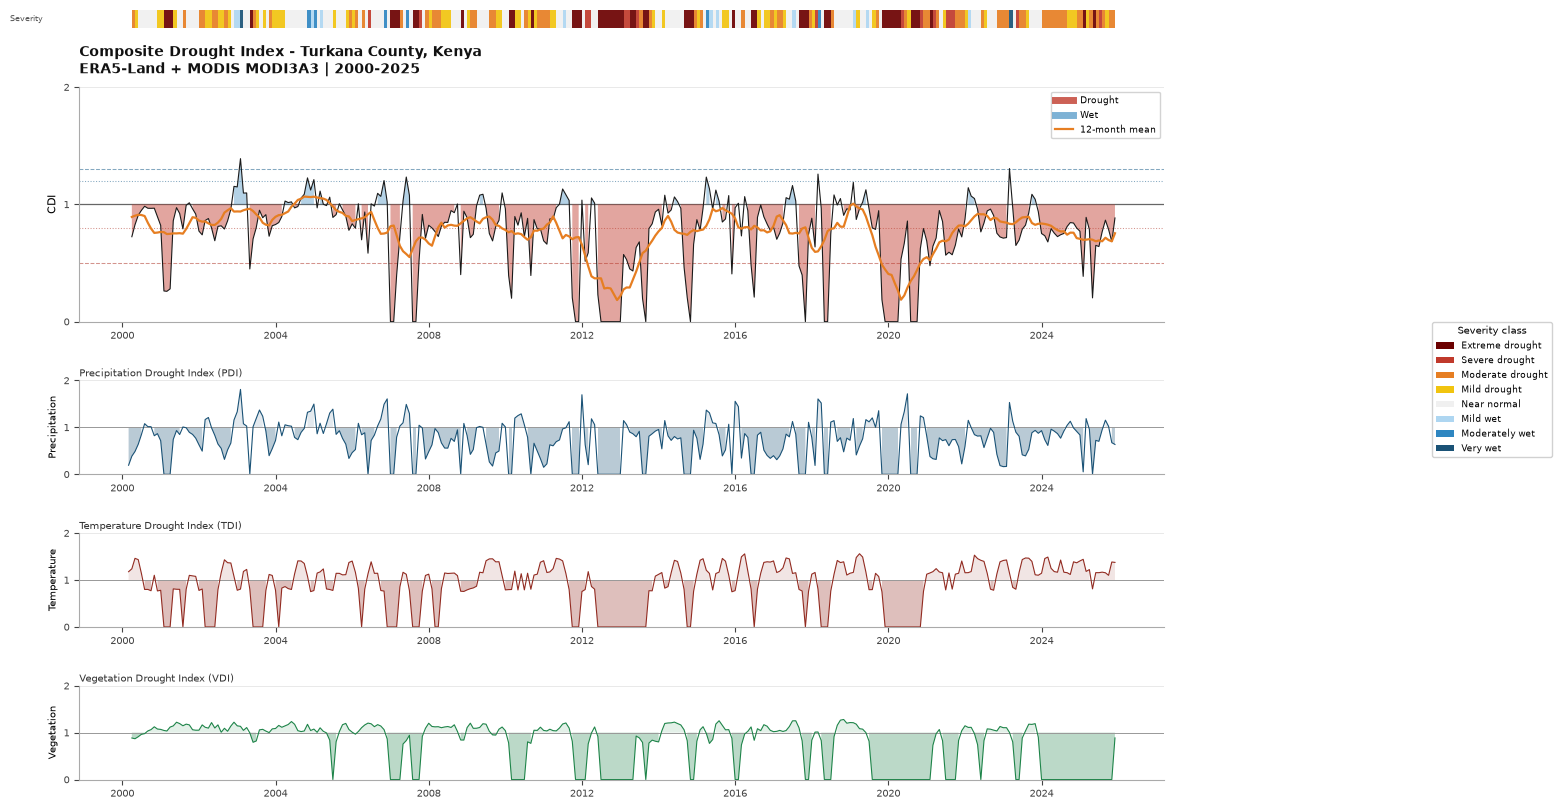

In [ ]:
#publication-Quality Plots

from drought_monitoring.plot import plot_timeseries
import matplotlib.pyplot as plt 

fig = plot_timeseries(
    df,
    title = "Composite Drought Index - Turkana County, Kenya",
    subtitle = "ERA5-Land + MODIS MODI3A3 | 2000-2025",
    show_components = True,  # show PDI, TDI, VDI sub-panels
    show_severity_bar = True,   # coloured severity stripe at top
)
fig.savefig("CDI_timeseries_Garissa.png", dpi=150, bbox_inches="tight")
plt.show()

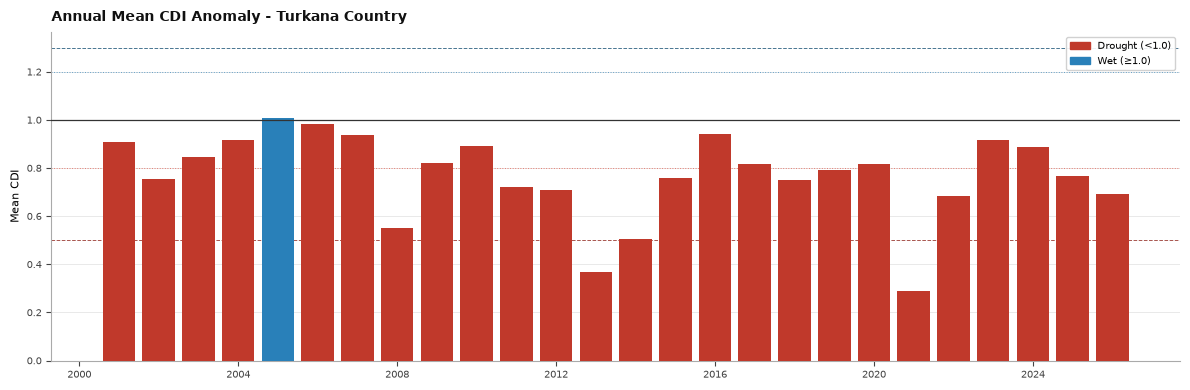

In [ ]:
#Anomaly bars
from drought_monitoring.plot import plot_anomaly_bars
fig2 = plot_anomaly_bars(
    df,
    column = "CDI",
    freq = "Y",
    title = "Annual Mean CDI Anomaly - Turkana Country",
)
fig.savefig("CDI_Annual_Garissa.png", dpi=150, bbox_inches="tight")
plt.show()
    

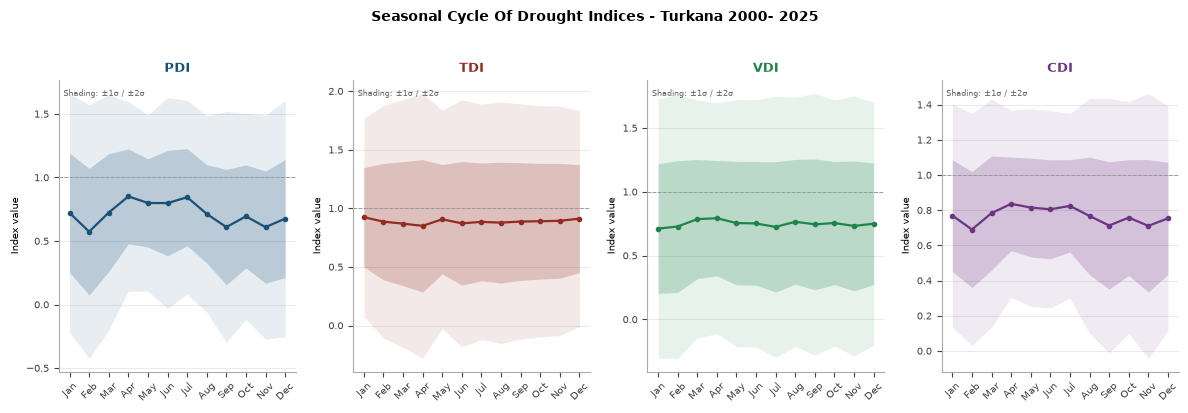

In [ ]:
#seasonal cycle
from drought_monitoring.plot import plot_seasonal_cycle

fig3 = plot_seasonal_cycle(
    df,
    title = "Seasonal Cycle Of Drought Indices - Turkana 2000- 2025",
)
fig3.savefig("CDI_seasonal_Garissa.png", dpi=150, bbox_inches="tight")
plt.show()



In [ ]:
import xarray as xr
import ee, shapely
from xee import helpers

_original_open_dataset = xr.open_dataset

import xarray as xr
import ee, shapely
from xee import helpers

if not getattr(xr.open_dataset, "_is_ee_patch", False):
    _original_open_dataset = xr.open_dataset

    def _patched_open_dataset(*args, **kwargs):
        if kwargs.get("engine") == "ee" and "scale" in kwargs:
            scale = kwargs.pop("scale")
            geometry = kwargs.pop("geometry", None)
            crs = kwargs.pop("crs", "EPSG:4326")

            if geometry is not None:
                geom_shapely = (
                    shapely.geometry.shape(geometry.getInfo())
                    if isinstance(geometry, ee.Geometry)
                    else geometry
                )
                grid_params = helpers.fit_geometry(
                    geometry=geom_shapely,
                    grid_crs=crs,
                    grid_scale=(scale, -scale),
                )
            else:
                grid_params = helpers.extract_grid_params(args[0])

            kwargs.update(grid_params)

        return _original_open_dataset(*args, **kwargs)

    _patched_open_dataset._is_ee_patch = True
    xr.open_dataset = _patched_open_dataset
    print("EE open_dataset patch applied.")
else:
    print("Patch already applied — skipping.")
# now run it — this call will use the patched function under the hood
from drought_monitoring.gee import yearly_drought_maps
ds = yearly_drought_maps(aoi, start_year=2000, end_year=2025)

print(ds)
print(f"Dimensions: {dict(ds.dims)}")
print(f"Variables: {list(ds.data_vars)}")

EE open_dataset patch applied.


RecursionError: maximum recursion depth exceeded

In [ ]:
#Spatial Maps and cloud Optimized GeoTIFF Export
from drought_monitoring.gee import yearly_drought_maps

print("Computing annual CDI maps (dask-parallel, may take 1-3 min)..")
ds = yearly_drought_maps(aoi, start_year=2000, end_year=2025)

print("\nDataset structure")
print(ds)
print(f"\nDimensions: {dict(ds.dims)}")
print(f"Variables: {list(ds.data_vars)}")

Computing annual CDI maps (dask-parallel, may take 1-3 min)..


TypeError: EarthEngineBackendEntrypoint.open_dataset() got an unexpected keyword argument 'scale'

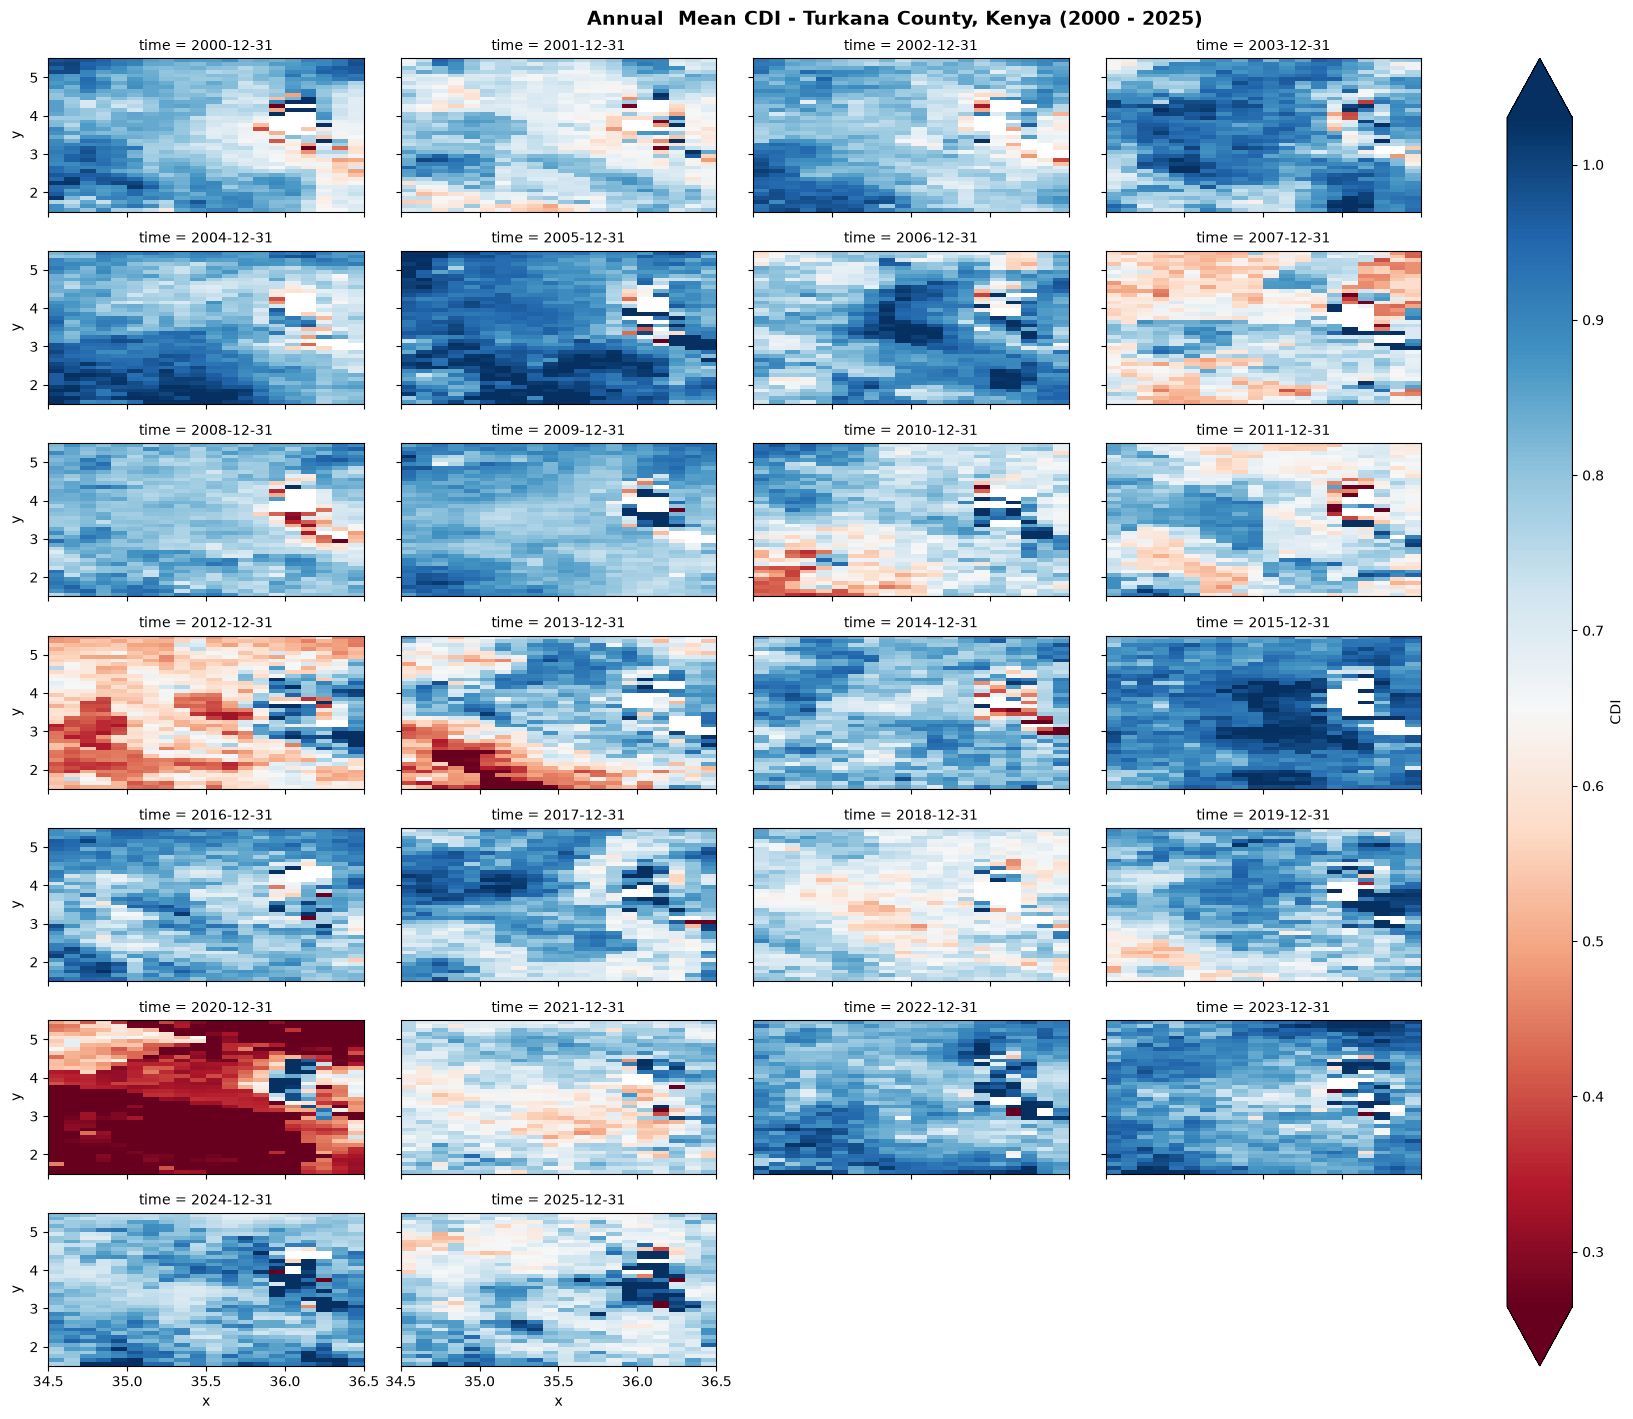

In [ ]:
#Quick matplotlib plot of all the years

import matplotlib.pyplot as plt

ds["CDI"].plot(
    col    ="time",
    col_wrap=4,
    cmap   ="RdBu",
    robust = True,
    figsize = (18, 14),
)
plt.suptitle("Annual  Mean CDI - Turkana County, Kenya (2000 - 2025)",
              y=1.01, fontsize=14, fontweight="bold")
plt.savefig("CDI_annual_maps.png", dpi=120, bbox_inches="tight")
plt.show()

In [ ]:
# snapshot of worst year (2020)
from drought_monitoring.plot import plot_map_snapshot
import matplotlib.pyplot as plt
import numpy as np

# Get the 2020 CDI data
cdi_2020 = ds["CDI"].sel(time="2020", method="nearest")
print("CDI shape:", cdi_2020.shape)
print("CDI dims:", cdi_2020.dims)

# Extract coordinates and values
lons = cdi_2020.coords['lon'].values
lats = cdi_2020.coords['lat'].values
data = cdi_2020.values

print(f"Lons shape: {lons.shape}, Lats shape: {lats.shape}, Data shape: {data.shape}")

# Create meshgrid if needed for proper coordinate alignment
if len(lons.shape) == 1 and len(lats.shape) == 1:
    lon_mesh, lat_mesh = np.meshgrid(lons, lats, indexing='ij')
    print(f"Created meshgrid: lon_mesh {lon_mesh.shape}, lat_mesh {lat_mesh.shape}")
else:
    lon_mesh, lat_mesh = lons, lats

# Now try plotting
try:
    fig_map = plot_map_snapshot(
        cdi_2020,
        title="CDI - Turkana County 2020 (Worst year on record)",
    )
except Exception as e:
    print(f"Error with DataArray input: {e}")
    print("Attempting alternative approach...")

plt.show()

CDI shape: (40, 20)
CDI dims: ('y', 'x')


KeyError: 'lon'

In [ ]:
#Export  to cloud optimized GeoTIFFs
#one COG per variable - one band per year -150 date as band description
#These can be streamed directly  in leafmap without any conversion

import os
from drought_monitoring.io import cdi_stack_to_cog  # Fix: correct module name
os.makedirs("Outputs", exist_ok=True)

paths = cdi_stack_to_cog(
    ds,
    output_dir = "outputs/",
    prefix  ="Garissa_2000_2025",
)
print("COG files written:")
for var, path in paths.items():
    size_mb = os.path.getsize(path) / 1_048_576
    print(f" {var}: {path} ({size_mb:.2f} MB)")

✓ COG written → outputs\Garissa_2000_2025_PDI.tif  (26 bands, 40×20 px, 0.20 MB)
✓ COG written → outputs\Garissa_2000_2025_TDI.tif  (26 bands, 40×20 px, 0.20 MB)
✓ COG written → outputs\Garissa_2000_2025_VDI.tif  (26 bands, 40×20 px, 0.21 MB)
✓ COG written → outputs\Garissa_2000_2025_CDI.tif  (26 bands, 40×20 px, 0.20 MB)
COG files written:
 PDI: C:\Users\user\drought-monitoring\Outputs\Garissa_2000_2025_PDI.tif (0.20 MB)
 TDI: C:\Users\user\drought-monitoring\Outputs\Garissa_2000_2025_TDI.tif (0.20 MB)
 VDI: C:\Users\user\drought-monitoring\Outputs\Garissa_2000_2025_VDI.tif (0.21 MB)
 CDI: C:\Users\user\drought-monitoring\Outputs\Garissa_2000_2025_CDI.tif (0.20 MB)


In [ ]:
# -- 0.5 Visualize in leafmap
import base64
import folium
import rasterio
import numpy as np
import matplotlib.pyplot as plt
import leafmap.foliumap as leafmap
from io import BytesIO
from PIL import Image

CARTO      = "https://{s}.basemaps.cartocdn.com/light_all/{z}/{x}/{y}{r}.png"
CARTO_ATTR = "Map tiles by CARTO, CC BY 3.0. Data by OpenStreetMap, ODbL."

def cog_band_to_overlay(tif_path, band=1, vmin=-2.0, vmax=2.0,
                        cmap_name="RdBu", opacity=0.75):
    """Read one band from a COG and return a base64 folium ImageOverlay."""
    with rasterio.open(tif_path) as src:
        data   = src.read(band).astype(float)
        bounds = src.bounds
        if src.nodata is not None:
            data[data == src.nodata] = np.nan

    norm = np.clip((data - vmin) / (vmax - vmin), 0, 1)
    cmap = plt.get_cmap(cmap_name)
    rgba = (cmap(norm) * 255).astype(np.uint8)
    rgba[np.isnan(data), 3] = 0          # transparent where nodata

    buf = BytesIO()
    Image.fromarray(rgba, mode="RGBA").save(buf, format="PNG")
    b64 = base64.b64encode(buf.getvalue()).decode()

    overlay = folium.raster_layers.ImageOverlay(
        image   = f"data:image/png;base64,{b64}",
        bounds  = [[bounds.bottom, bounds.left], [bounds.top, bounds.right]],
        opacity = opacity,
        name    = f"Band {band}",
    )
    return overlay, bounds

# Ensure 'paths' is defined by running the export cell first
try:
    paths
except NameError:
    from drought_monitoring.io import cdi_stack_to_cog
    import os
    os.makedirs("Outputs", exist_ok=True)
    paths = cdi_stack_to_cog(
        ds,
        output_dir = "outputs/",
        prefix  ="Turkana_2000_2025",
)

m = leafmap.Map(center=[3.3, 35.5], zoom=7, tiles=CARTO, attr=CARTO_ATTR)
overlay, bounds = cog_band_to_overlay(str(paths["CDI"]), band=1)
overlay.add_to(m)
folium.LayerControl().add_to(m)
m